# Stage 6 – Day-ahead Occupancy Forecasting (Machine-Learning Extension)

**MMA3001 Project – Occupancy-driven ventilation assessment (Tom Gregory)**

Stages 4–5 used the **measured** occupancy. Demand-controlled ventilation (DCV) driven by a live people-counter met the CO2 criteria with about 90 % less outdoor air than the fixed design rate. This stage asks whether a **forecast** could do the same job:

> Can tomorrow's occupancy of G.20 be predicted well enough, from the calendar and past counts, to schedule its ventilation a day ahead without relying on a live sensor?

**Prediction contract** (Notebook 5.6.1)

| Item | Definition |
|---|---|
| Target | Mean occupancy of each 15-minute slot of the next day [people] |
| Issued | At local midnight, for the whole day |
| Allowed inputs | Time of day, weekday, Victorian public holidays; occupancy on **earlier days only** |
| Decision supported | The day's ventilation schedule (outdoor-air flow) |
| Consequence of error | **Under**-prediction means under-ventilation and high CO2; over-prediction wastes energy |

**Workflow (Week 5)**

| Section | Content | Course link |
|---|---|---|
| A | Set-up, features, leakage control | 5.6.5, 5.6.8 |
| B | Data audit and time-ordered splits | 5.6.3, 5.6.6, 5.6.9 |
| C | Baselines, and tuning the decision tree with time-aware cross-validation | 5.5.6, 5.2.6–5.2.8, 5.6.7 |
| D | Cross-validated comparison and model selection | 5.5.9 |
| E | Chronological validation: overall, busy-period and daily errors; neural network | 5.5.8, 5.4 |
| F | What the model learned: permutation importance and residuals | 5.2.13, 5.5.7 |
| G | One-time final test, with a bootstrap interval | 5.5.10, 5.5.11 |
| H | Does forecast-scheduled ventilation meet the CO2 criteria? | Stage 4 model |
| I | Engineering interpretation and limitations | |

**Runtime:** about 2 minutes.

## A. Set-up and features

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.tree import DecisionTreeRegressor

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import occvent
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    import occvent

from occvent.co2model import RoomParameters, exact_solution, occupancy_from_grid, step_mean_concentration
from occvent.config import ESTIMATED_VOLUME_M3, LOCAL_TIMEZONE
from occvent.design import dcv_ventilation, evaluate_ventilation, find_min_dcv_rate, outdoor_air_energy
from occvent.forecast import (FEATURE_COLUMNS, VIC_PUBLIC_HOLIDAYS, LagBaseline, bootstrap_mae_by_day, build_models,
                              daily_slot_table, make_features, period_mask, predict_nonnegative,
                              regression_metrics, slots_to_steps)
from occvent.io import load_processed
from occvent.metrics import rolling_mean

PROCESSED = ROOT / "data" / "processed" / "G20_occupancy_1min.csv.gz"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not PROCESSED.exists():
    raise FileNotFoundError(f"{PROCESSED} not found. Run `python -m occvent.prepare --raw data/raw/<zip>` first.")

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "ink": "#0b0b0b", "grey": "#52514e", "light": "#898781"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

grid = load_processed(PROCESSED)
occ, DT, _ = occupancy_from_grid(grid)
table = daily_slot_table(grid["headcount"])          # local date x 96 fifteen-minute slots
F = make_features(table)
FEATURES = list(FEATURE_COLUMNS)
X, y = F[FEATURES], F["target"].to_numpy()
print(f"occvent {occvent.__version__}; slot table {table.shape[0]} days x {table.shape[1]} slots")
print(f"Modelling rows: {len(F):,} (first {F.index[0][0]}, last {F.index[-1][0]}); {len(FEATURES)} features")
print(", ".join(FEATURES))

occvent 0.6.0; slot table 781 days x 96 slots
Modelling rows: 72,216 (first 2024-03-31, last 2026-04-22); 29 features
tod_sin1, tod_cos1, tod_sin2, tod_cos2, tod_sin3, tod_cos3, dow_0, dow_1, dow_2, dow_3, dow_4, dow_5, dow_6, holiday, workday, work_tod_sin1, work_tod_cos1, work_tod_sin2, work_tod_cos2, work_tod_sin3, work_tod_cos3, lag_1d, lag_7d, lag_mean_4w, lag_1d_2h, lag_7d_2h, lag_mean_4w_2h, prev_day_mean, prev_week_mean


**Features and leakage control.** Every occupancy feature is computed from **earlier calendar days** (1-day and 7-day lags of the same slot, a 4-week mean, 2-hour smoothed versions of these, and the previous day's and week's means). The forecast issued at midnight therefore never uses anything from the day it predicts (Notebook 5.6.5). A unit test changes one day's data and checks that no feature on or before that day changes.

Calendar features: three daily harmonics (sine/cosine pairs, as in a Fourier series) for the time of day, the weekday, a public-holiday flag, a work-day flag, and the harmonics multiplied by the work-day flag. The last group lets a *linear* model have a different daily shape on work days.

**Not used:** teaching-period (semester) dates. Official Monash dates for 2024–25 could not be verified, so the model has to infer term changes from the lags. This is a stated limitation (Section I).

The first 4 weeks are dropped, because their lags are not yet available. Learned preprocessing (standardisation) sits inside each model's `Pipeline`, so it is fitted on training rows only (Notebook 5.6.8).

## B. Data audit and time-ordered splits

The deployment question is **future** operation, so the split must be chronological (Notebook 5.6.6):

| Set | Period | Role |
|---|---|---|
| Training | 31 Mar 2024 – 30 Jun 2025 | Fit models |
| Validation | 1 Jul – 31 Dec 2025 | Compare models (holdout) |
| Development = training + validation | 31 Mar 2024 – 31 Dec 2025 | Time-aware cross-validation; final refit |
| **Test** | 1 Jan – 22 Apr 2026 | Used **once**, at the end (Section G) |

             days     rows  mean occupancy  zero slots [%]  busy slots (>= 5) [%]    max
training    457.0  43808.0            0.93           55.47                   4.00  65.72
validation  184.0  17660.0            0.76           57.72                   2.40  49.62
test        112.0  10748.0            0.95           60.26                   4.32  57.26


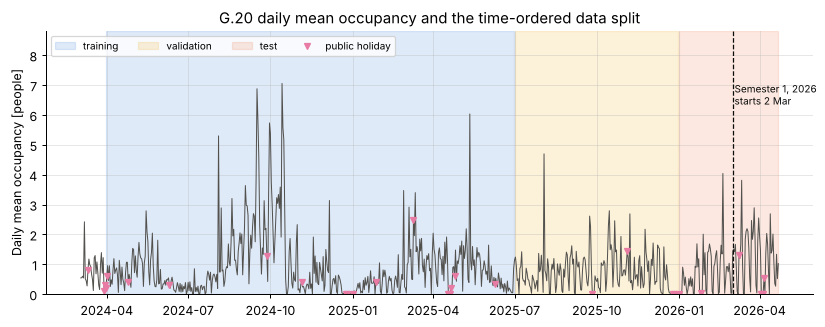

In [2]:
dev = period_mask(F.index, "2024-01-01", "2025-12-31")
tr = period_mask(F.index, "2024-01-01", "2025-06-30")
va = period_mask(F.index, "2025-07-01", "2025-12-31")
te = period_mask(F.index, "2026-01-01", "2026-12-31")
assert not (tr & va).any() and not (dev & te).any() and (tr | va).sum() == dev.sum()

BUSY = 5.0   # people: the "busy" operating region where ventilation matters most
audit = pd.DataFrame({name: {"days": F.index[m].get_level_values("date").nunique(), "rows": int(m.sum()),
                             "mean occupancy": y[m].mean(), "zero slots [%]": 100 * np.mean(y[m] == 0),
                             f"busy slots (>= {BUSY:.0f}) [%]": 100 * np.mean(y[m] >= BUSY), "max": y[m].max()}
                      for name, m in [("training", tr), ("validation", va), ("test", te)]}).T
print(audit.round(2).to_string())

daily = table.mean(axis=1)
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily.values, color=C["grey"], lw=0.8)
for (start, end, color, label) in [("2024-03-31", "2025-06-30", C["blue"], "training"),
                                   ("2025-07-01", "2025-12-31", C["yellow"], "validation"),
                                   ("2026-01-01", "2026-04-22", C["orange"], "test")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.15, label=label)
hol = [pd.Timestamp(d) for d in sorted(VIC_PUBLIC_HOLIDAYS) if daily.index[0] <= pd.Timestamp(d) <= daily.index[-1]]
ax.plot(hol, daily.reindex(hol).values, ls="none", marker="v", ms=5, color=C["magenta"], label="public holiday")
ax.axvline(pd.Timestamp("2026-03-02"), color=C["ink"], lw=1, ls="--")
ax.text(pd.Timestamp("2026-03-04"), daily.max() * 0.9, "Semester 1, 2026\nstarts 2 Mar", fontsize=8, color=C["ink"])
ax.set_ylabel("Daily mean occupancy [people]")
ax.set_ylim(0, daily.max() * 1.25)
ax.set_title("G.20 daily mean occupancy and the time-ordered data split")
ax.legend(loc="upper left", ncol=4, fontsize=8)
save(fig, "stage6_data_splits")

**Audit findings.**

* The room is **empty most of the time**, and busy slots ($\ge$ 5 people) are rare.
* Strong seasonality is visible, with low summer and mid-year breaks. Most public holidays are close to zero, though not all (for example, Labour Day 2025).
* The test period starts in the summer break and includes the start of Semester 1, 2026 (2 Mar, from the published Monash principal dates). This is a hard test, because term start must be picked up from the lags alone.
* There are a few isolated very busy days, such as early-August Sundays (consistent with Open Day). No feature can anticipate these.

## C. Baselines and tuning the decision tree

**Baselines** (Notebook 5.5.6): a model must beat simple rules to show useful skill.

* `DummyRegressor`: predicts the training mean everywhere.
* **Seasonal naive**: "same slot last week" (`lag_7d`).
* **4-week mean**: the same slot, averaged over the last 4 weeks and smoothed over ±1 hour (`lag_mean_4w_2h`).

**Primary metric: RMSE.** Large errors, especially missed busy periods, matter most for ventilation, and RMSE weights them more heavily than MAE (Notebook 5.5.2). MAE, R² and the bias are also reported for every model.

**Time-aware cross-validation** (Notebook 5.6.7): `TimeSeriesSplit` with 5 folds on the development data, with a one-day (96-row) gap between training and validation in each fold. Each fold trains only on the past.

The decision tree's `max_depth` and `min_samples_leaf` are chosen by cross-validated RMSE. Training and validation errors are compared to see where under- and over-fitting start (Notebook 5.2.7).

fold 1: train 2024-03-31 .. 2024-07-15  ->  validate 2024-07-16 .. 2024-10-31
fold 2: train 2024-03-31 .. 2024-10-30  ->  validate 2024-10-31 .. 2025-02-14
fold 3: train 2024-03-31 .. 2025-02-13  ->  validate 2025-02-14 .. 2025-06-01
fold 4: train 2024-03-31 .. 2025-05-31  ->  validate 2025-06-01 .. 2025-09-16
fold 5: train 2024-03-31 .. 2025-09-15  ->  validate 2025-09-16 .. 2025-12-31

Tree grid (18 settings x 5 folds) in 16 s
min_samples_leaf    50     200    500
max_depth                            
2                 2.139  2.139  2.139
4                 2.092  2.071  2.091
6                 2.092  2.061  2.089
8                 2.119  2.063  2.089
10                2.136  2.066  2.090
12                2.138  2.067  2.091
Selected: max_depth = 6, min_samples_leaf = 200 (CV RMSE 2.061)


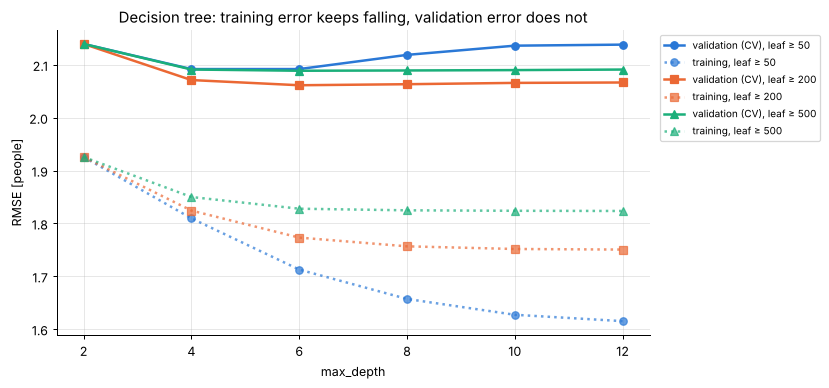

In [3]:
tss = TimeSeriesSplit(n_splits=5, gap=96)
Xd, yd = X[dev], y[dev]
for k, (i_tr, i_va) in enumerate(tss.split(Xd), start=1):
    d_tr, d_va = Xd.index[i_tr].get_level_values("date"), Xd.index[i_va].get_level_values("date")
    print(f"fold {k}: train {d_tr.min()} .. {d_tr.max()}  ->  validate {d_va.min()} .. {d_va.max()}")

t0 = time.perf_counter()
rows = []
for depth in (2, 4, 6, 8, 10, 12):
    for leaf in (50, 200, 500):
        cv = cross_validate(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=0), Xd, yd,
                            cv=tss, scoring="neg_root_mean_squared_error", return_train_score=True)
        rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                     "train RMSE": -cv["train_score"].mean(), "CV RMSE": -cv["test_score"].mean()})
tuning = pd.DataFrame(rows)
best = tuning.loc[tuning["CV RMSE"].idxmin()]
TREE_DEPTH, TREE_LEAF = int(best["max_depth"]), int(best["min_samples_leaf"])
print(f"\nTree grid ({len(tuning)} settings x 5 folds) in {time.perf_counter() - t0:.0f} s")
print(tuning.pivot(index="max_depth", columns="min_samples_leaf", values="CV RMSE").round(3).to_string())
print(f"Selected: max_depth = {TREE_DEPTH}, min_samples_leaf = {TREE_LEAF} (CV RMSE {best['CV RMSE']:.3f})")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for leaf, color, marker in [(50, C["blue"], "o"), (200, C["orange"], "s"), (500, C["aqua"], "^")]:
    t = tuning[tuning["min_samples_leaf"] == leaf]
    ax.plot(t["max_depth"], t["CV RMSE"], color=color, marker=marker, label=f"validation (CV), leaf ≥ {leaf}")
    ax.plot(t["max_depth"], t["train RMSE"], color=color, marker=marker, ls=":", alpha=0.7, label=f"training, leaf ≥ {leaf}")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE [people]")
ax.set_title("Decision tree: training error keeps falling, validation error does not")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
save(fig, "stage6_tree_tuning")

## D. Cross-validated comparison and model selection

All candidates are evaluated with the same five time-ordered folds. The neural network is left out here because training it five times is slow; it is compared on the validation holdout in Section E instead.

**Selection rule (fixed before looking at the test set):** lowest mean CV RMSE. If another model is within 2 % of the best, prefer the simpler and more interpretable one (linear < tree).

                   model  CV RMSE mean  CV RMSE sd  CV MAE mean
            mean (Dummy)         2.339       0.857        1.276
seasonal naive (lag 7 d)         2.723       0.831        1.010
       4-week mean (2 h)         2.175       0.562        0.905
       linear regression         2.060       0.606        0.921
           decision tree         2.061       0.683        0.865

RMSE in each fold:
                          fold 1  fold 2  fold 3  fold 4  fold 5
mean (Dummy)               3.740   1.575   2.525   1.822   2.035
seasonal naive (lag 7 d)   4.003   1.836   3.001   2.255   2.520
4-week mean (2 h)          3.053   1.630   2.378   1.833   1.982
linear regression          2.976   1.447   2.338   1.696   1.843
decision tree              3.109   1.359   2.322   1.653   1.864

Selected model: linear regression


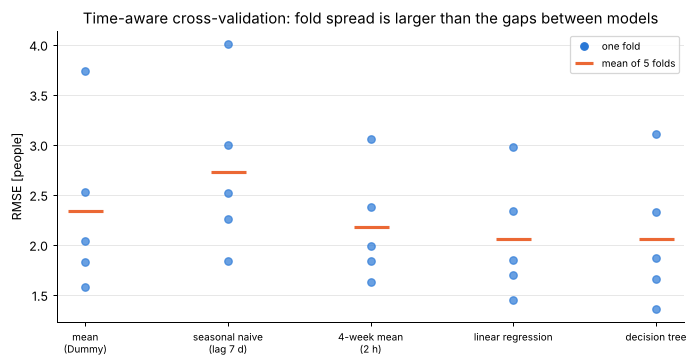

In [4]:
models = build_models(tree_depth=TREE_DEPTH, tree_min_leaf=TREE_LEAF)
candidates = {"mean (Dummy)": DummyRegressor(), "seasonal naive (lag 7 d)": LagBaseline("lag_7d"),
              "4-week mean (2 h)": LagBaseline("lag_mean_4w_2h"),
              "linear regression": models["linear"], "decision tree": models["tree"]}
cv_rows, fold_rmse = [], {}
for name, est in candidates.items():
    cv = cross_validate(est, Xd, yd, cv=tss, scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error"))
    fold_rmse[name] = -cv["test_neg_root_mean_squared_error"]
    cv_rows.append({"model": name, "CV RMSE mean": fold_rmse[name].mean(), "CV RMSE sd": fold_rmse[name].std(ddof=1),
                    "CV MAE mean": -cv["test_neg_mean_absolute_error"].mean()})
cv_table = pd.DataFrame(cv_rows)
print(cv_table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("\nRMSE in each fold:")
print(pd.DataFrame(fold_rmse, index=[f"fold {k}" for k in range(1, 6)]).T.round(3).to_string())

ranked = cv_table[cv_table["model"].isin(["linear regression", "decision tree"])].set_index("model")["CV RMSE mean"]
best_rmse = ranked.min()
SELECTED = next(m for m in ["linear regression", "decision tree"] if ranked[m] <= 1.02 * best_rmse)
print(f"\nSelected model: {SELECTED}")

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (name, vals) in enumerate(fold_rmse.items()):
    ax.plot(np.full(vals.size, i), vals, ls="none", marker="o", color=C["blue"], alpha=0.7)
    ax.plot(i, vals.mean(), marker="_", ms=28, mew=2.5, color=C["orange"])
ax.plot([], [], ls="none", marker="o", color=C["blue"], label="one fold")
ax.plot([], [], ls="none", marker="_", ms=14, mew=2.5, color=C["orange"], label="mean of 5 folds")
ax.set_xticks(range(len(fold_rmse)), [n.replace(" (", "\n(") for n in fold_rmse], fontsize=8)
ax.set_ylabel("RMSE [people]")
ax.set_title("Time-aware cross-validation: fold spread is larger than the gaps between models")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
save(fig, "stage6_cv_comparison")

**What this shows.** Linear regression has a lower RMSE than every baseline **in every fold**; the decision tree does in four of the five folds. The two learned models have almost the same mean CV RMSE (2.060 vs 2.061), and the differences between folds (different seasons) are far larger than the difference between them. The selection rule therefore picks the simpler, interpretable linear model. The fold-to-fold spread is a reminder that one score is not a property of the model; it depends on the period tested (Notebook 5.5.9).

## E. Chronological validation holdout

Train on 31 Mar 2024 – 30 Jun 2025; validate on Jul–Dec 2025. Errors are reported **overall**, in the **busy region** (actual ≥ 5 people, where ventilation matters), and at the **daily** scale (daily mean occupancy, which sets energy use). The busy-region **bias** shows the *direction* of the error (Notebook 5.5.8).

The neural network (`MLPRegressor`, 32-16 hidden neurons, scaled inputs, early stopping) is trained with three random seeds, because one seed does not show stability (Notebook 5.4.11).

In [5]:
def evaluate(name, pred, mask):
    yt = y[mask]
    out = {"model": name, **regression_metrics(yt, pred)}
    b = yt >= BUSY
    busy = regression_metrics(yt[b], pred[b])
    out.update({"busy MAE": busy["MAE"], "busy bias": busy["bias"]})
    d = F.index[mask].get_level_values("date")
    daily_true = pd.Series(yt).groupby(d).mean()
    daily_pred = pd.Series(pred).groupby(d).mean()
    out["daily-mean MAE"] = regression_metrics(daily_true, daily_pred)["MAE"]
    return out

t0 = time.perf_counter()
val_rows, val_pred = [], {}
for name, est in candidates.items():
    fitted = clone(est).fit(X[tr], y[tr])
    val_pred[name] = predict_nonnegative(fitted, X[va])
    val_rows.append(evaluate(name, val_pred[name], va))
for seed in (0, 1, 2):
    mlp = build_models(random_state=seed)["mlp"].fit(X[tr], y[tr])
    p = predict_nonnegative(mlp, X[va])
    val_rows.append(evaluate(f"neural network (seed {seed})", p, va))
    print(f"MLP seed {seed}: {mlp[-1].n_iter_} epochs (early stopping)")
val_table = pd.DataFrame(val_rows)
print(f"\nValidation holdout ({va.sum():,} slots, {(y[va] >= BUSY).sum()} busy) in {time.perf_counter() - t0:.0f} s")
print(val_table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

MLP seed 0: 249 epochs (early stopping)
MLP seed 1: 79 epochs (early stopping)
MLP seed 2: 144 epochs (early stopping)

Validation holdout (17,660 slots, 423 busy) in 42 s
                   model   MAE  RMSE     R2   bias  busy MAE  busy bias  daily-mean MAE
            mean (Dummy) 1.099 2.041 -0.008  0.177     8.864     -8.864           0.526
seasonal naive (lag 7 d) 0.868 2.539 -0.559  0.008     7.809     -7.338           0.488
       4-week mean (2 h) 0.761 1.980  0.052  0.003     7.940     -7.930           0.433
       linear regression 0.716 1.868  0.156  0.050     7.665     -7.665           0.380
           decision tree 0.721 1.877  0.147 -0.036     7.949     -7.949           0.390
 neural network (seed 0) 0.837 2.031  0.002  0.136     7.390     -7.369           0.440
 neural network (seed 1) 0.779 1.946  0.084  0.054     7.717     -7.708           0.408
 neural network (seed 2) 0.804 1.985  0.047  0.047     7.774     -7.772           0.417


**What this shows.**

* The learned models reduce RMSE and MAE compared with every baseline, but R² stays low. Most of the slot-to-slot variation in an informal breakout space is **not predictable** from the calendar and history: whether a group drops in at 2 pm on a Tuesday is close to random.
* In the **busy region**, every model **under-predicts heavily** (large negative bias). A forecast regresses towards typical values and cannot anticipate a crowd. For ventilation, this is the dangerous direction.
* The neural network is no better than linear regression and varies between seeds, so its extra complexity is not justified here.

## F. What the model learned

**Permutation importance** (Notebook 5.2.13): shuffle one feature in the validation data and measure how much the RMSE increases. A large increase means the model relies on that feature. This describes the *model*, not causation in the room.

Permutation importance (linear regression, validation): increase in RMSE [people]
lag_1d_2h         0.0367
work_tod_cos1     0.0247
lag_1d            0.0053
tod_sin1          0.0053
prev_day_mean     0.0048
tod_cos1          0.0048
workday           0.0047
work_tod_sin1     0.0042
dow_0             0.0038
lag_mean_4w_2h    0.0037


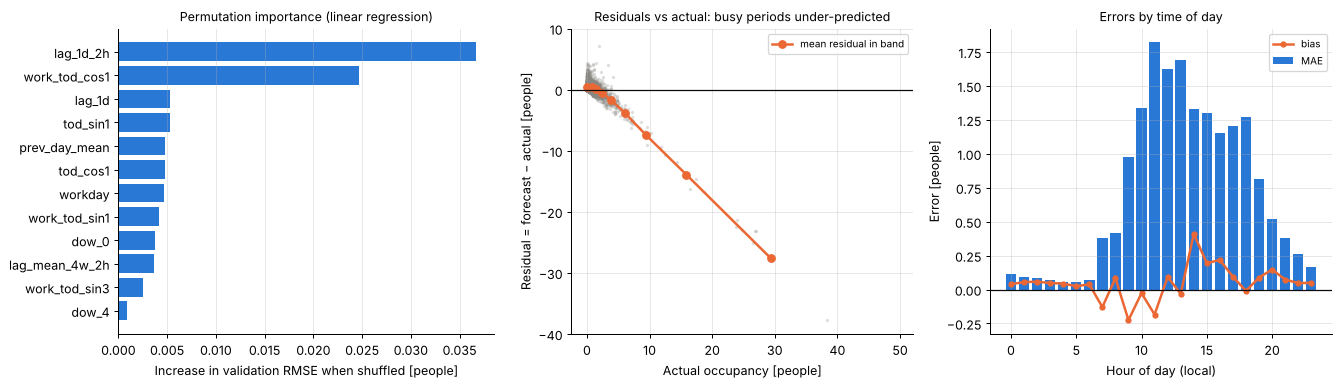

In [6]:
final_name = SELECTED
model_tr = clone(candidates[final_name]).fit(X[tr], y[tr])
pi = permutation_importance(model_tr, X[va], y[va], scoring="neg_root_mean_squared_error", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"Permutation importance ({final_name}, validation): increase in RMSE [people]")
print(imp.head(10).round(4).to_string())

top = imp.head(12)[::-1]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax1.barh(top.index, top.values, color=C["blue"])
ax1.set_xlabel("Increase in validation RMSE when shuffled [people]")
ax1.set_title(f"Permutation importance ({final_name})", fontsize=10)
ax1.grid(axis="y", visible=False)

yv, pv = y[va], val_pred[final_name]
bins = np.array([0, 0.5, 1, 2, 3, 5, 8, 12, 20, 70])
which = np.digitize(yv, bins) - 1
mid = [yv[which == i].mean() for i in range(len(bins) - 1) if np.any(which == i)]
res = [np.mean(pv[which == i] - yv[which == i]) for i in range(len(bins) - 1) if np.any(which == i)]
ax2.scatter(yv[::7], (pv - yv)[::7], s=3, alpha=0.2, color=C["light"], rasterized=True)
ax2.plot(mid, res, color=C["orange"], marker="o", label="mean residual in band")
ax2.axhline(0, color=C["ink"], lw=1)
ax2.set_xlabel("Actual occupancy [people]")
ax2.set_ylabel("Residual = forecast − actual [people]")
ax2.set_title("Residuals vs actual: busy periods under-predicted", fontsize=10)
ax2.set_ylim(-40, 10)
ax2.legend(fontsize=8)

slot = F.index[va].get_level_values("slot").to_numpy()
hour = slot // 4
r = pd.DataFrame({"hour": hour, "res": pv - yv, "abs": np.abs(pv - yv)}).groupby("hour").mean()
ax3.bar(r.index, r["abs"], color=C["blue"], label="MAE")
ax3.plot(r.index, r["res"], color=C["orange"], marker="o", ms=4, label="bias")
ax3.axhline(0, color=C["ink"], lw=1)
ax3.set_xlabel("Hour of day (local)")
ax3.set_ylabel("Error [people]")
ax3.set_title("Errors by time of day", fontsize=10)
ax3.legend(fontsize=8)
fig.tight_layout()
save(fig, "stage6_diagnostics")

**What this shows.** The model relies mostly on **yesterday's smoothed occupancy at the same time** (`lag_1d_2h`) and on the **work-day daily cycle** (`work_tod_cos1`). Every other feature adds little on its own: several are partly redundant with each other, and permutation importance only measures what each one adds while the others stay in place. The model has learned "how busy this time of a work day usually is, at the room's current level of use", which is the predictable part.

The residuals fall steadily as actual occupancy rises. The forecast rarely exceeds a few people, so the busier the room, the further it falls short: about −28 people in the busiest band. The errors are concentrated in the daytime, when the room is used, and the overall bias by hour is small. The problem is the busy moments, not a systematic offset.

## G. One-time final test

The selected model is refitted on all development data (31 Mar 2024 – 31 Dec 2025) and evaluated **once** on Jan–Apr 2026 (Notebook 5.5.10). The baselines have nothing to tune, so they are shown for reference. The **95 % bootstrap interval** of the test MAE resamples whole days (errors within a day are correlated). It describes the precision of this one number, not a prediction interval (Notebook 5.5.11).

Test period: 10,748 slots, 464 busy
                       model   MAE  RMSE     R2   bias  busy MAE  busy bias  daily-mean MAE
                mean (Dummy) 1.283 2.389 -0.001 -0.067     7.690     -7.690           0.695
    seasonal naive (lag 7 d) 0.903 2.734 -0.311 -0.058     5.791     -5.026           0.528
           4-week mean (2 h) 0.748 2.114  0.216 -0.125     5.607     -5.452           0.442
linear regression (selected) 0.763 2.020  0.285 -0.037     5.742     -5.740           0.410

Selected model test MAE 0.763 people; 95 % day-block bootstrap interval 0.662 – 0.872


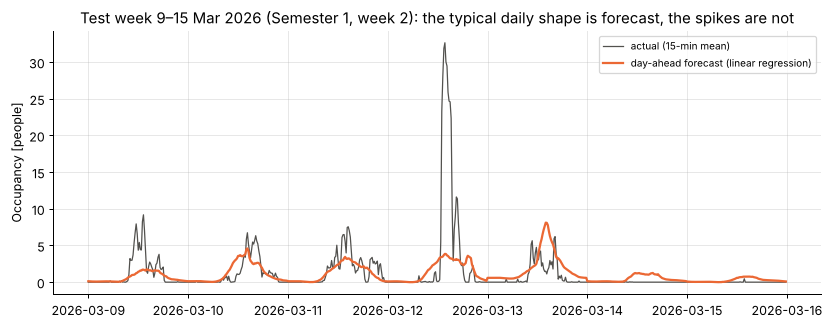

In [7]:
final_model = clone(candidates[final_name]).fit(X[dev], y[dev])
test_pred = predict_nonnegative(final_model, X[te])
test_rows = [evaluate(name, predict_nonnegative(clone(candidates[name]).fit(X[dev], y[dev]), X[te]), te)
             for name in ["mean (Dummy)", "seasonal naive (lag 7 d)", "4-week mean (2 h)"]]
test_rows.append(evaluate(f"{final_name} (selected)", test_pred, te))
test_table = pd.DataFrame(test_rows)
print(f"Test period: {te.sum():,} slots, {(y[te] >= BUSY).sum()} busy")
print(test_table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
lo, hi = bootstrap_mae_by_day(np.abs(test_pred - y[te]), F.index[te].get_level_values("date").to_numpy(), n_boot=2000)
print(f"\nSelected model test MAE {np.mean(np.abs(test_pred - y[te])):.3f} people; 95 % day-block bootstrap interval {lo:.3f} – {hi:.3f}")

# One week of the test period, in semester: actual vs forecast.
week = (pd.Timestamp("2026-03-09"), pd.Timestamp("2026-03-15"))
d_te = pd.to_datetime(pd.Index(F.index[te].get_level_values("date")))
in_week = np.asarray((d_te >= week[0]) & (d_te <= week[1]))
slots = F.index[te][in_week]
t_axis = pd.to_datetime(pd.Index(slots.get_level_values("date"))) + pd.to_timedelta(slots.get_level_values("slot") * 15, unit="min")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t_axis, y[te][in_week], color=C["grey"], lw=1, label="actual (15-min mean)")
ax.plot(t_axis, test_pred[in_week], color=C["orange"], lw=1.8, label=f"day-ahead forecast ({final_name})")
ax.set_ylabel("Occupancy [people]")
ax.set_title("Test week 9–15 Mar 2026 (Semester 1, week 2): the typical daily shape is forecast, the spikes are not")
ax.legend(loc="upper right", fontsize=8)
save(fig, "stage6_test_week")

**What this shows.**

* On the untouched test period, the selected model has the lowest **RMSE** (the primary metric), the highest R² and the lowest daily-mean error.
* Its MAE is essentially tied with the 4-week-mean baseline (0.763 vs 0.748 people, well inside the bootstrap interval), and in the busy region it is no better than the baselines.
* The test errors are similar to the validation errors (RMSE 2.02 vs 1.87), so the model was not tuned to its validation period.
* The forecast follows the typical daily rhythm, but the crowd spikes are missed, such as the 30+ people at midday on Thu 12 Mar. The busy-region bias is again strongly negative.

## H. Does forecast-scheduled ventilation meet the CO2 criteria?

This is the engineering test of the forecast. The DCV rule from Stage 4 is fed with the **forecast** instead of the live count, optionally with a **safety factor** $s$ on the per-person rate:

$$Q(t) = \max\big(Q_{floor},\; s\,q_p\,\hat N(t)\big),\qquad Q_{floor} = 50\ \text{L/s}.$$

The room's CO2 is then simulated with the **actual** occupancy (exact solution, Stage 2), and compared with sensor-driven DCV, $Q = \max(Q_{floor}, q_p N)$. Here $q_p$ is re-derived from the development period only (Stage 4 method), so no test data influence the design.

* The **validation** period (model trained on the training period) is used to see what $s$ would be needed.
* The **test** period (model trained on development) then checks the conclusion.

In [8]:
P = RoomParameters(volume_m3=ESTIMATED_VOLUME_M3["G20"])
Q_FLOOR = 50.0
local = grid.index.tz_convert(LOCAL_TIMEZONE)
local_date = np.asarray(local.date)

def minutes_between(start, end):
    return (local_date >= pd.Timestamp(start).date()) & (local_date <= pd.Timestamp(end).date())

m_dev = minutes_between("2024-01-01", "2025-12-31")
QP = find_min_dcv_rate(occ[m_dev], P, DT, q_floor_lps=Q_FLOOR).root
print(f"DCV per-person rate from development data: q_p = {QP:.2f} L/s per person")

def ventilation_study(pred, mask_rows, start, end, factors):
    mm = minutes_between(start, end)
    n_true = occ[mm]
    n_hat = slots_to_steps(pd.Series(pred, index=F.index[mask_rows]), grid.index[mm])
    if not np.all(np.isfinite(n_hat)):
        raise ValueError("forecast missing for some minutes")
    loc = local[mm]
    out = []
    strategies = [("sensor DCV (live count)", dcv_ventilation(n_true, QP, Q_FLOOR))]
    strategies += [(f"forecast DCV, s = {s:g}", dcv_ventilation(n_hat, s * QP, Q_FLOOR)) for s in factors]
    curves = {}
    for name, q in strategies:
        c = exact_solution(n_true, q, P, DT)
        cm = step_mean_concentration(c, n_true, q, P, DT)
        r8 = pd.Series(rolling_mean(cm, 480), index=loc)
        days_8h = int((r8.resample("D").max() > 850).sum())
        days_pk = int((pd.Series(cm, index=loc).resample("D").max() > 1000).sum())
        e = outdoor_air_energy(q, DT, q.size, delta_t_k=7.0)
        out.append({"strategy": name, "worst 8-h [ppm]": np.nanmax(r8.to_numpy()),
                    "worst 8-h window ends": f"{r8.idxmax():%a %d %b %H:%M}", "peak [ppm]": cm.max(),
                    "days > 850 (8-h)": days_8h, "days > 1000 (peak)": days_pk,
                    "mean flow [L/s]": q.mean(), "energy [MWh]": e["energy_kwh"] / 1000})
        curves[name] = (cm, q)
    n_days = len(pd.unique(local_date[mm]))
    return pd.DataFrame(out), curves, n_hat, n_true, loc, n_days

FACTORS = (1, 2, 4, 8)
val_study, _, _, _, _, n_val_days = ventilation_study(val_pred[final_name], va, "2025-07-01", "2025-12-31", FACTORS)
print(f"\nVALIDATION period ({n_val_days} days), model trained on the training period")
print(val_study.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
test_study, curves, n_hat_te, n_true_te, loc_te, n_test_days = ventilation_study(test_pred, te, "2026-01-01", "2026-12-31", FACTORS)
print(f"\nTEST period ({n_test_days} days), model trained on development data")
print(test_study.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

DCV per-person rate from development data: q_p = 12.06 L/s per person

VALIDATION period (184 days), model trained on the training period
               strategy  worst 8-h [ppm] worst 8-h window ends  peak [ppm]  days > 850 (8-h)  days > 1000 (peak)  mean flow [L/s]  energy [MWh]
sensor DCV (live count)            777.8      Tue 14 Oct 22:24       850.1                 0                   0             51.8           1.9
    forecast DCV, s = 1           1598.7      Sun 03 Aug 19:22      2311.4                11                  13             50.1           1.9
    forecast DCV, s = 2           1598.7      Sun 03 Aug 19:22      2311.4                 6                  11             52.0           1.9
    forecast DCV, s = 4           1598.7      Sun 03 Aug 19:22      2311.4                 2                   4             65.2           2.4
    forecast DCV, s = 8           1534.3      Sun 03 Aug 19:20      2257.3                 2                   2             99.2           3.

Worst 8-h window (forecast DCV, s = 4): Thu 19 Feb 19:05 – 03:05, 8-h mean CO2 1193 ppm
  in that window: actual mean occupancy 7.7 (max 59); forecast mean 0.56 (max 1.44) people


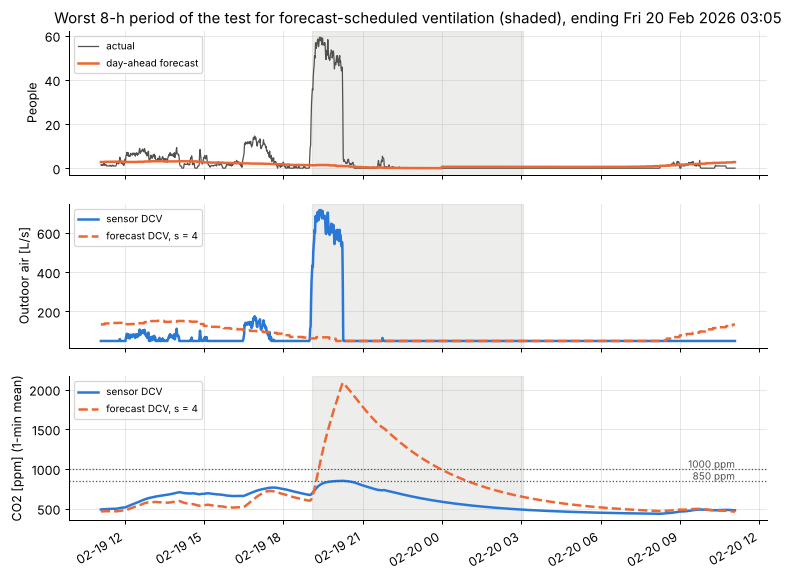

In [9]:
# The worst 8-hour period of the test for forecast-scheduled ventilation with s = 4.
name_f = "forecast DCV, s = 4"
cm_f, q_f = curves[name_f]
cm_s, q_s = curves["sensor DCV (live count)"]
r8_f = pd.Series(rolling_mean(cm_f, 480), index=loc_te)
t_end = r8_f.idxmax()                                  # end of the worst trailing 8-h window
in8 = np.asarray((loc_te > t_end - pd.Timedelta(hours=8)) & (loc_te <= t_end))
print(f"Worst 8-h window ({name_f}): {t_end - pd.Timedelta(hours=8):%a %d %b %H:%M} – {t_end:%H:%M}, "
      f"8-h mean CO2 {r8_f.max():.0f} ppm")
print(f"  in that window: actual mean occupancy {n_true_te[in8].mean():.1f} (max {n_true_te[in8].max():.0f}); "
      f"forecast mean {n_hat_te[in8].mean():.2f} (max {n_hat_te[in8].max():.2f}) people")
mask = np.asarray((loc_te > t_end - pd.Timedelta(hours=16)) & (loc_te <= t_end + pd.Timedelta(hours=8)))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
t = loc_te[mask]
ax1.plot(t, n_true_te[mask], color=C["grey"], lw=1, label="actual")
ax1.plot(t, n_hat_te[mask], color=C["orange"], label="day-ahead forecast")
ax1.set_ylabel("People")
ax1.legend(fontsize=8, loc="upper left")
ax1.axvspan(t_end - pd.Timedelta(hours=8), t_end, color=C["light"], alpha=0.15)
ax1.set_title(f"Worst 8-h period of the test for forecast-scheduled ventilation (shaded), ending {t_end:%a %d %b %Y %H:%M}")
for ax in (ax2, ax3):
    ax.axvspan(t_end - pd.Timedelta(hours=8), t_end, color=C["light"], alpha=0.15)
ax2.plot(t, q_s[mask], color=C["blue"], label="sensor DCV")
ax2.plot(t, q_f[mask], color=C["orange"], ls="--", label=name_f)
ax2.set_ylabel("Outdoor air [L/s]")
ax2.legend(fontsize=8, loc="upper left")
ax3.plot(t, cm_s[mask], color=C["blue"], label="sensor DCV")
ax3.plot(t, cm_f[mask], color=C["orange"], ls="--", label=name_f)
for lvl, txt in [(850, "850 ppm"), (1000, "1000 ppm")]:
    ax3.axhline(lvl, color=C["grey"], lw=1, ls=":")
    ax3.text(t[-1], lvl + 15, txt, fontsize=8, color=C["grey"], ha="right")
ax3.set_ylabel("CO2 [ppm] (1-min mean)")
ax3.legend(fontsize=8, loc="upper left")
fig.autofmt_xdate()
save(fig, "stage6_forecast_ventilation")

**What this shows.**

* **Sensor-driven DCV** meets both criteria on every day of both periods, as in Stage 4.
* **Forecast-driven DCV with $s = 1$** exceeds the 8-hour limit on 11 of 184 validation days and 12 of 112 test days. Raising the safety factor reduces the failing days, but **no tested value reaches compliance on every day**. Even $s = 8$ still fails on 2 days in each period, while using about twice the average outdoor air of sensor DCV. Multiplying a forecast that is close to zero still gives close to zero, so no factor can fix a crowd the forecast did not expect.
* The worst periods are **events outside normal patterns**. In validation it was Sunday 3 Aug 2025, an early-August Sunday consistent with Open Day. In the test it was the evening of Thu 19 Feb 2026: up to 59 people after 7 pm, while the forecast was about half a person. The calendar and history features cannot anticipate these cases, but a live sensor responds to them immediately (the blue curve).

## I. Engineering interpretation and limitations

**Findings**

1. A day-ahead forecast of G.20's 15-minute occupancy, using taught models (linear regression and a decision tree), beats the naive baselines on the primary metric (RMSE) in time-aware cross-validation, on the validation holdout and on the untouched test period. On the test period its MAE is tied with the best baseline (a 4-week average). The selected model is the simpler, interpretable **linear regression**. The neural network adds no skill.
2. The skill is **modest** (R² well below 0.5). The predictable part is the weekly rhythm and recent usage level. Individual drop-in groups and events are essentially unpredictable from this information.
3. Forecast errors are **directional**: busy periods are under-predicted by several people on average. For ventilation this is the unsafe direction.
4. **Forecast-scheduled ventilation does not meet the CO2 criteria** on irregular days, whatever safety factor is used. A forecast is therefore **not a substitute for a live sensor** in this room. The Stage 4 recommendation stands: demand-controlled ventilation should be driven by the live people-count (or a CO2 sensor).
5. A forecast is still useful for **planning**: typical daily profiles, pre-conditioning, and estimating energy use. Known events (room bookings, Open Day, orientation) should be added as features or as manual overrides.

**Limitations**

* No teaching-period feature, because the official 2024–25 dates could not be verified. Adding the academic calendar, and room-booking data if available, is the most promising improvement.
* Only taught models were used, with modest tuning. More complex models might reduce the error slightly, but they cannot predict events that leave no trace in the inputs.
* One room. The 15-minute target, the 5-person busy threshold and the 2 % selection tolerance are engineering choices.
* The test period is about 16 weeks (summer break plus the start of Semester 1). It does not cover a full year of seasons.
* The physics evaluation inherits all Stage 4–5 assumptions (estimated room volume, generation rate, well-mixed air).